# Baseline Text Classification Models

This notebook establishes classical machine learning baselines for primary ticket category classification.

The experiments compare word-level and character-level TF-IDF representations with Logistic Regression and Linear SVM.

Evaluation focuses on Macro-F1, weighted F1, accuracy, per-class performance, and confusion matrices.

The goal is to identify a strong classical baseline before evaluating more advanced multilingual transformer models.

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from transformers import Trainer
from sklearn.metrics import accuracy_score, f1_score
from transformers import TrainingArguments
from transformers import AutoModelForSequenceClassification
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
from datasets import Dataset
from transformers import DataCollatorWithPadding
from sklearn.metrics import f1_score
import re
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, f1_score, precision_score)
import torch
import torch.nn as nn
from transformers import Trainer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score
import inspect
import joblib
import shutil
import json
import sys



PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

train_df = pd.read_csv(RAW_DATA_DIR / "train.csv")
validation_df = pd.read_csv(RAW_DATA_DIR / "validation.csv")

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)

Train shape: (4000, 8)
Validation shape: (800, 8)


In [2]:
X_train = train_df["text"]
y_train = train_df["category"]

X_validation = validation_df["text"]
y_validation = validation_df["category"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("Number of classes:", y_train.nunique())
print("Classes:", sorted(y_train.unique()))

Training samples: 4000
Validation samples: 800
Number of classes: 11
Classes: ['account_promo', 'app_technical', 'delivery_delay', 'food_quality', 'general_inquiry', 'lost_item', 'order_missing_wrong', 'payment_refund', 'ride_trip_issue', 'safety_conduct', 'spam_irrelevant']


In [ ]:
def evaluate_model(model, X, y):
    predictions = model.predict(X)

    accuracy = accuracy_score(y, predictions)
    macro_f1 = f1_score(y, predictions, average="macro")
    weighted_f1 = f1_score(y, predictions, average="weighted")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Macro-F1:    {macro_f1:.4f}")
    print(f"Weighted-F1: {weighted_f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y, predictions))

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "predictions": predictions
    }

In [ ]:
word_lr = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

word_lr.fit(X_train, y_train)

word_lr_results = evaluate_model(
    word_lr,
    X_validation,
    y_validation
)

Accuracy:    0.4425
Macro-F1:    0.4300
Weighted-F1: 0.4154

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.58      0.26      0.36        72
      app_technical       0.77      0.16      0.26        64
     delivery_delay       0.38      0.40      0.39       120
       food_quality       0.62      0.14      0.23        56
    general_inquiry       0.87      0.33      0.47        40
          lost_item       0.71      0.12      0.21        40
order_missing_wrong       0.34      0.22      0.27        96
     payment_refund       0.33      0.87      0.48       144
    ride_trip_issue       0.62      0.64      0.63       112
     safety_conduct       0.90      0.28      0.43        32
    spam_irrelevant       1.00      1.00      1.00        24

           accuracy                           0.44       800
          macro avg       0.65      0.40      0.43       800
       weighted avg       0.54      0.44      0.42       800

In [ ]:
# Use Linear SVM with the same word TF-IDF features for a fair comparison
word_svm = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

word_svm.fit(X_train, y_train)

word_svm_results = evaluate_model(
    word_svm,
    X_validation,
    y_validation
)

Accuracy:    0.5537
Macro-F1:    0.5906
Weighted-F1: 0.5467

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.74      0.56      0.63        72
      app_technical       0.79      0.36      0.49        64
     delivery_delay       0.51      0.42      0.46       120
       food_quality       0.41      0.21      0.28        56
    general_inquiry       0.60      0.65      0.63        40
          lost_item       0.84      0.78      0.81        40
order_missing_wrong       0.33      0.30      0.32        96
     payment_refund       0.43      0.83      0.57       144
    ride_trip_issue       0.73      0.62      0.67       112
     safety_conduct       0.80      0.62      0.70        32
    spam_irrelevant       0.89      1.00      0.94        24

           accuracy                           0.55       800
          macro avg       0.64      0.58      0.59       800
       weighted avg       0.59      0.55      0.55       800

In [6]:
# Use character n-grams to capture spelling, transliteration, and multilingual patterns
char_lr = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

char_lr.fit(X_train, y_train)

char_lr_results = evaluate_model(
    char_lr,
    X_validation,
    y_validation
)

Accuracy:    0.5100
Macro-F1:    0.4927
Weighted-F1: 0.4843

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.72      0.47      0.57        72
      app_technical       0.64      0.11      0.19        64
     delivery_delay       0.44      0.63      0.52       120
       food_quality       1.00      0.12      0.22        56
    general_inquiry       1.00      0.38      0.55        40
          lost_item       0.62      0.12      0.21        40
order_missing_wrong       0.48      0.34      0.40        96
     payment_refund       0.37      0.78      0.50       144
    ride_trip_issue       0.63      0.73      0.68       112
     safety_conduct       1.00      0.44      0.61        32
    spam_irrelevant       1.00      0.96      0.98        24

           accuracy                           0.51       800
          macro avg       0.72      0.46      0.49       800
       weighted avg       0.62      0.51      0.48       800

In [7]:
# Use Linear SVM with character n-grams for a stronger character baseline
char_svm = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3
        )
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

char_svm.fit(X_train, y_train)

char_svm_results = evaluate_model(
    char_svm,
    X_validation,
    y_validation
)

Accuracy:    0.6200
Macro-F1:    0.6503
Weighted-F1: 0.6228

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.80      0.72      0.76        72
      app_technical       0.86      0.38      0.52        64
     delivery_delay       0.56      0.62      0.59       120
       food_quality       0.86      0.34      0.49        56
    general_inquiry       0.93      0.70      0.80        40
          lost_item       0.32      0.55      0.41        40
order_missing_wrong       0.43      0.40      0.41        96
     payment_refund       0.49      0.73      0.58       144
    ride_trip_issue       0.84      0.78      0.81       112
     safety_conduct       0.96      0.72      0.82        32
    spam_irrelevant       0.92      1.00      0.96        24

           accuracy                           0.62       800
          macro avg       0.73      0.63      0.65       800
       weighted avg       0.67      0.62      0.62       800

In [ ]:
# Combine word-level and character-level TF-IDF representations
word_char_features = FeatureUnion([
    (
        "word_tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "char_tfidf",
        TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3
        )
    )
])

word_char_svm = Pipeline([
    (
        "features",
        word_char_features
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

word_char_svm.fit(X_train, y_train)

word_char_results = evaluate_model(
    word_char_svm,
    X_validation,
    y_validation
)

Accuracy:    0.6088
Macro-F1:    0.6437
Weighted-F1: 0.6103

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.81      0.60      0.69        72
      app_technical       0.90      0.44      0.59        64
     delivery_delay       0.59      0.59      0.59       120
       food_quality       0.70      0.34      0.46        56
    general_inquiry       0.86      0.75      0.80        40
          lost_item       0.51      0.70      0.59        40
order_missing_wrong       0.31      0.31      0.31        96
     payment_refund       0.47      0.74      0.58       144
    ride_trip_issue       0.85      0.76      0.80       112
     safety_conduct       0.88      0.69      0.77        32
    spam_irrelevant       0.83      1.00      0.91        24

           accuracy                           0.61       800
          macro avg       0.70      0.63      0.64       800
       weighted avg       0.65      0.61      0.61       800

In [ ]:
# Use text and language as model inputs
train_features = train_df[["text", "language"]]
validation_features = validation_df[["text", "language"]]

# Combine character TF-IDF text features with one-hot encoded language
char_language_features = ColumnTransformer([
    (
        "char_tfidf",
        TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3
        ),
        "text"
    ),
    (
        "language",
        OneHotEncoder(handle_unknown="ignore"),
        ["language"]
    )
])

# Train Linear SVM using text features and language metadata
char_language_svm = Pipeline([
    (
        "features",
        char_language_features
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

char_language_svm.fit(
    train_features,
    y_train
)

char_language_results = evaluate_model(
    char_language_svm,
    validation_features,
    y_validation
)

Accuracy:    0.6138
Macro-F1:    0.6444
Weighted-F1: 0.6178

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.80      0.72      0.76        72
      app_technical       0.90      0.41      0.56        64
     delivery_delay       0.55      0.61      0.58       120
       food_quality       0.87      0.36      0.51        56
    general_inquiry       0.93      0.65      0.76        40
          lost_item       0.33      0.55      0.41        40
order_missing_wrong       0.41      0.39      0.40        96
     payment_refund       0.48      0.69      0.57       144
    ride_trip_issue       0.84      0.78      0.81       112
     safety_conduct       0.92      0.75      0.83        32
    spam_irrelevant       0.83      1.00      0.91        24

           accuracy                           0.61       800
          macro avg       0.71      0.63      0.64       800
       weighted avg       0.67      0.61      0.62       800

In [10]:
# Use text and channel as model inputs
train_features = train_df[["text", "channel"]]
validation_features = validation_df[["text", "channel"]]

# Combine character TF-IDF text features with one-hot encoded channel
char_channel_features = ColumnTransformer([
    (
        "char_tfidf",
        TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3
        ),
        "text"
    ),
    (
        "channel",
        OneHotEncoder(handle_unknown="ignore"),
        ["channel"]
    )
])

# Train Linear SVM using text features and channel metadata
char_channel_svm = Pipeline([
    (
        "features",
        char_channel_features
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

char_channel_svm.fit(
    train_features,
    y_train
)

char_channel_results = evaluate_model(
    char_channel_svm,
    validation_features,
    y_validation
)

Accuracy:    0.6188
Macro-F1:    0.6529
Weighted-F1: 0.6230

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.80      0.71      0.75        72
      app_technical       0.88      0.36      0.51        64
     delivery_delay       0.56      0.62      0.59       120
       food_quality       0.88      0.38      0.53        56
    general_inquiry       0.94      0.72      0.82        40
          lost_item       0.32      0.55      0.40        40
order_missing_wrong       0.43      0.40      0.41        96
     payment_refund       0.48      0.72      0.58       144
    ride_trip_issue       0.85      0.78      0.81       112
     safety_conduct       0.92      0.72      0.81        32
    spam_irrelevant       0.96      1.00      0.98        24

           accuracy                           0.62       800
          macro avg       0.73      0.63      0.65       800
       weighted avg       0.67      0.62      0.62       800

In [11]:
# Combine subject and text into a single text input
train_features = train_df[["subject", "text", "channel"]].copy()
validation_features = validation_df[["subject", "text", "channel"]].copy()

train_features["subject"] = train_features["subject"].fillna("")
validation_features["subject"] = validation_features["subject"].fillna("")

train_features["combined_text"] = (
    train_features["subject"] + " " + train_features["text"]
)

validation_features["combined_text"] = (
    validation_features["subject"] + " " + validation_features["text"]
)

# Combine character TF-IDF with channel metadata
subject_text_channel_features = ColumnTransformer([
    (
        "char_tfidf",
        TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3
        ),
        "combined_text"
    ),
    (
        "channel",
        OneHotEncoder(handle_unknown="ignore"),
        ["channel"]
    )
])

# Train Linear SVM using subject, text, and channel
subject_text_channel_svm = Pipeline([
    (
        "features",
        subject_text_channel_features
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

subject_text_channel_svm.fit(
    train_features,
    y_train
)

subject_text_channel_results = evaluate_model(
    subject_text_channel_svm,
    validation_features,
    y_validation
)

Accuracy:    0.6238
Macro-F1:    0.6545
Weighted-F1: 0.6251

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.79      0.74      0.76        72
      app_technical       0.85      0.34      0.49        64
     delivery_delay       0.59      0.65      0.62       120
       food_quality       0.88      0.38      0.53        56
    general_inquiry       0.89      0.80      0.84        40
          lost_item       0.32      0.55      0.41        40
order_missing_wrong       0.40      0.38      0.39        96
     payment_refund       0.50      0.70      0.58       144
    ride_trip_issue       0.83      0.78      0.80       112
     safety_conduct       0.85      0.72      0.78        32
    spam_irrelevant       1.00      1.00      1.00        24

           accuracy                           0.62       800
          macro avg       0.72      0.64      0.65       800
       weighted avg       0.67      0.62      0.63       800

In [12]:
# Get B8 predictions and decision scores for error analysis
b8_predictions = subject_text_channel_svm.predict(validation_features)
b8_scores = subject_text_channel_svm.decision_function(validation_features)

print("Validation predictions:", len(b8_predictions))
print("Decision score shape:", b8_scores.shape)

Validation predictions: 800
Decision score shape: (800, 11)


In [13]:
# Create a table containing the actual and predicted categories
error_analysis_df = validation_features.copy()
error_analysis_df["actual_category"] = y_validation.values
error_analysis_df["predicted_category"] = b8_predictions

errors = error_analysis_df[
    error_analysis_df["actual_category"] != error_analysis_df["predicted_category"]
].copy()

print("Total validation samples:", len(error_analysis_df))
print("Misclassified samples:", len(errors))
print("Error rate:", len(errors) / len(error_analysis_df))

Total validation samples: 800
Misclassified samples: 301
Error rate: 0.37625


In [14]:
# Find the category pairs that are confused most often
confusion_pairs = (
    errors.groupby(
        ["actual_category", "predicted_category"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

confusion_pairs.head(15)

,actual_category,predicted_category,count
34,order_missing_wrong,payment_refund,27
38,payment_refund,lost_item,25
15,food_quality,delivery_delay,19
13,delivery_delay,payment_refund,19
12,delivery_delay,order_missing_wrong,18
33,order_missing_wrong,lost_item,17
7,app_technical,order_missing_wrong,15
46,ride_trip_issue,payment_refund,14
2,account_promo,payment_refund,14
31,order_missing_wrong,delivery_delay,12


In [15]:
# Inspect representative examples from the most common confusion pairs
pairs_to_inspect = [
    ("order_missing_wrong", "payment_refund"),
    ("payment_refund", "lost_item"),
    ("food_quality", "delivery_delay")
]

for actual, predicted in pairs_to_inspect:
    print("=" * 80)
    print(f"ACTUAL: {actual}  |  PREDICTED: {predicted}")
    print("=" * 80)

    pair_errors = errors[
        (errors["actual_category"] == actual) &
        (errors["predicted_category"] == predicted)
    ]

    for _, row in pair_errors.head(5).iterrows():
        print(f"\nSubject: {row['subject']}")
        print(f"Channel: {row['channel']}")
        print(f"Text: {row['text']}")
        print("-" * 80)

ACTUAL: order_missing_wrong  |  PREDICTED: payment_refund

Subject: 
Channel: chat
Text: Here are the details of my request.
I have kept a copy of the confirmation.
The record I can see is SIMD-N5XCHYN.
I am using my usual device for this request.
Our delivery includes a main dish we never selected.
Can the support desk follow up?
--------------------------------------------------------------------------------

Subject: My service request
Channel: email
Text: Dear RideEat support,

pls advise on this situation.
The promised combo arrived without its accompanying beverage.
I do not remember the exact minute I opened the service, but I have the ref.
I have kept the confrmation rather than deleting it from the device.
I am giving as much background as I can remember so the record can be located.
I checked that this is the support address shown inside the app.
If you need another detail about the booking, pls let me know which one.
I am using my usual device for this request.
Can the suppo

In [16]:
# Inspect payment_refund tickets predicted as lost_item
pair_errors = errors[
    (errors["actual_category"] == "payment_refund") &
    (errors["predicted_category"] == "lost_item")
]

for _, row in pair_errors.head(10).iterrows():
    print("=" * 80)
    print(f"Subject: {row['subject']}")
    print(f"Channel: {row['channel']}")
    print(f"Text: {row['text']}")

Subject: විස්තර පරීක්ෂා කරන්න
Channel: email
Text: මට මේක බලලා දෙන්න පුළුවන්ද? එක පාරටම විස්තර කියන්න ටිකක් අමාරුයි. මම කලින් පණිවිඩ ටිකත් බලලා මේක ලියන්නේ. මම පණිවිඩය ලියන අතරේ වෙන වැඩකට යන්න වුණා. මොන විකාරයක්ද මේ!!! ඉතාම නරක සේවාවක්! රිසිට් එකේ ගානට වඩා වැඩිපුර අය කරලා. යොමු අංකය හොයන්න ටිකක් වෙලා ගියා. පිළිතුරක් දෙන්න.
Subject: 
Channel: chat
Text: කරුණාකර මේක බලන්න.
රිසිට් එකේ ගානට වඩා වැඩිපුර අය කරලා.
මගේ පවුලේ කෙනෙක් පණිවිඩය ලියන්න උදව් කළා.
ගෙවීම් සටහනේ රු. 1500 කියලා තියෙනවා.
තහවුරු කිරීමේ විස්තර මම තියාගෙන ඉන්නවා.
ඊළඟට මොකක්ද කරන්නේ?
Subject: 
Channel: chat
Text: meka therum ganna ba mama phone phone eken baluwe receipt eke ganata wada wadipura aran mama balagena inne 🤦
Subject: මේ ගැන බලන්න
Channel: email
Text: මගේ  ඉල්ලීම බලන්න
එක
පාරටම විස්තර කියන්න ටිකක් අමාරුයි
මගේ    ගෙදර  අයගෙන් ඇහුවට පස්සේ ආයෙත් විස්තර කියවලා බැලුවා    රිසිට් එකේ ගානට වඩා වැඩිපුර
අය කරලා
තහවුරු
කිරීමේ විස්තර මම තියාගෙන ඉන්නවා මම ආයෙත් විස්තර  පරීක්ෂා  කළා මේ  ගැන හොයලා  දැනුම් දෙන්න
Subject: 
Channel:

In [17]:
# Train the best feature setup with balanced class weights
balanced_svm = Pipeline([
    (
        "features",
        subject_text_channel_features
    ),
    (
        "classifier",
        LinearSVC(
            class_weight="balanced",
            random_state=42
        )
    )
])

balanced_svm.fit(
    train_features,
    y_train
)

balanced_svm_results = evaluate_model(
    balanced_svm,
    validation_features,
    y_validation
)

Accuracy:    0.6312
Macro-F1:    0.6550
Weighted-F1: 0.6346

Classification Report:
                     precision    recall  f1-score   support

      account_promo       0.78      0.79      0.79        72
      app_technical       0.80      0.38      0.51        64
     delivery_delay       0.61      0.65      0.63       120
       food_quality       0.87      0.46      0.60        56
    general_inquiry       0.63      0.80      0.70        40
          lost_item       0.30      0.62      0.41        40
order_missing_wrong       0.45      0.39      0.42        96
     payment_refund       0.53      0.63      0.58       144
    ride_trip_issue       0.92      0.78      0.84       112
     safety_conduct       0.75      0.75      0.75        32
    spam_irrelevant       0.96      1.00      0.98        24

           accuracy                           0.63       800
          macro avg       0.69      0.66      0.66       800
       weighted avg       0.67      0.63      0.63       800

##  XLM-RoBERTa

This experiment fine-tunes a multilingual XLM-RoBERTa model for primary ticket category classification.

The model is evaluated using the same metrics as the classical baselines, with Macro-F1 as the primary metric.

In [3]:
# Define a stable label mapping for the 11 primary categories
labels = sorted(train_df["category"].unique())

label2id = {
    label: idx
    for idx, label in enumerate(labels)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

print("Number of classes:", len(labels))
print("Label mapping:")
for idx, label in id2label.items():
    print(idx, "->", label)

Number of classes: 11
Label mapping:
0 -> account_promo
1 -> app_technical
2 -> delivery_delay
3 -> food_quality
4 -> general_inquiry
5 -> lost_item
6 -> order_missing_wrong
7 -> payment_refund
8 -> ride_trip_issue
9 -> safety_conduct
10 -> spam_irrelevant


In [4]:
# Load the multilingual tokenizer used by XLM-RoBERTa
MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)

Tokenizer: xlm-roberta-base
Vocabulary size: 250002


In [20]:
sample_texts = train_df["text"].iloc[:3].tolist()

for i, text in enumerate(sample_texts, start=1):
    tokens = tokenizer(
        text,
        truncation=True,
        max_length=256
    )

    print(f"Sample {i}")
    print("Original:", text[:150])
    print("Token count:", len(tokens["input_ids"]))
    print("Tokens:", tokenizer.convert_ids_to_tokens(tokens["input_ids"])[:20])
    print()

Sample 1
Original: I selected the service earlier today. I need help with the following situation. The fare was supposed to be LKR 3050, but a different sum was collecte
Token count: 46
Tokens: ['<s>', '▁I', '▁selected', '▁the', '▁service', '▁earlier', '▁today', '.', '▁I', '▁need', '▁help', '▁with', '▁the', '▁following', '▁situation', '.', '▁The', '▁fare', '▁was', '▁supposed']

Sample 2
Original: The screen shows the reference SIMQ-V9LU2KD
Can you check the details below
The packet arrived but half the items on the receipt are absent
Can you he
Token count: 43
Tokens: ['<s>', '▁The', '▁screen', '▁shows', '▁the', '▁reference', '▁SIM', 'Q', '-', 'V', '9', 'LU', '2', 'K', 'D', '▁Can', '▁you', '▁check', '▁the', '▁details']

Sample 3
Original: uh hello agent: rideeat  call karata  thanks mokakda
prashne? customer:  me gana kiyannai  liwwe. details hoyala

liyanna tikak wela giya. agent: thaw
Token count: 123
Tokens: ['<s>', '▁uh', '▁hell', 'o', '▁agent', ':', '▁ride', 'e', 'at', '▁call', '▁

In [21]:
token_lengths = train_df["text"].apply(
    lambda text: len(
        tokenizer(
            text,
            truncation=False,
            add_special_tokens=True
        )["input_ids"]
    )
)

print(token_lengths.describe(percentiles=[0.90, 0.95, 0.99]))

count    4000.000000
mean       79.106500
std        33.604196
min        15.000000
50%        71.000000
90%       127.000000
95%       139.000000
99%       169.010000
max       223.000000
Name: text, dtype: float64


In [6]:
# Keep only text and primary category
train_model_df = train_df[["text", "category"]].copy()
validation_model_df = validation_df[["text", "category"]].copy()

# Convert category labels to numeric IDs
train_model_df["label"] = train_model_df["category"].map(label2id)
validation_model_df["label"] = validation_model_df["category"].map(label2id)

# Convert pandas DataFrames to Hugging Face datasets
train_dataset = Dataset.from_pandas(
    train_model_df[["text", "label"]],
    preserve_index=False
)

validation_dataset = Dataset.from_pandas(
    validation_model_df[["text", "label"]],
    preserve_index=False
)

print(train_dataset)
print(validation_dataset)

Dataset({
    features: ['text', 'label'],
    num_rows: 4000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 800
})


In [8]:
# Set the maximum number of tokens per ticket
MAX_LENGTH = 256

# Tokenize ticket text without padding every ticket to 256 tokens
def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,       # Truncate text only if it exceeds MAX_LENGTH
        max_length=MAX_LENGTH
    )

# Tokenize the training and validation datasets
train_tokenized = train_dataset.map(
    tokenize_batch,
    batched=True
)

validation_tokenized = validation_dataset.map(
    tokenize_batch,
    batched=True
)

# Pad each batch dynamically to reduce unnecessary memory usage
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8
)

# Check the resulting datasets
print(train_tokenized)
print(validation_tokenized)
print("Dynamic padding collator ready.")

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 4000
})
Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 800
})
Dynamic padding collator ready.


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    label2id=label2id,
    id2label=id2label
)

print("Model:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)
print("Model type:", model.config.model_type)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: xlm-roberta-base
Number of labels: 11
Model type: xlm-roberta


In [ ]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory: 6.0 GB


In [ ]:
training_args = TrainingArguments(
    output_dir="../models/xlmr_primary",
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=True,
    logging_strategy="steps",
    logging_steps=50,
    report_to="none",
    seed=42
)

print(training_args)

TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start

In [9]:
# Calculate evaluation metrics for the classifier
def compute_metrics(eval_pred):
    # Separate model logits and the true category labels
    logits, labels = eval_pred
    # Convert logits into predicted category IDs
    predictions = np.argmax(logits, axis=-1)

    # Calculate accuracy and F1 scores
    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(labels, predictions, average="macro")
    weighted_f1 = f1_score(labels, predictions, average="weighted")

    # Return metrics for validation and model selection
    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=validation_tokenized,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Trainer created successfully.")

Trainer created successfully.


In [ ]:
model.to("cuda")
model.train()

batch = train_tokenized.select(range(4))

batch = {
    key: torch.tensor(batch[key]).to("cuda")
    for key in ["input_ids", "attention_mask"]
}

batch["labels"] = torch.tensor(
    train_tokenized.select(range(4))["label"]
).to("cuda")

outputs = model(**batch)

print("Loss:", outputs.loss.item())
print("Logits shape:", outputs.logits.shape)

Loss: 2.2872796058654785
Logits shape: torch.Size([4, 11])


In [30]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,4.102780,1.388525,0.562500,0.410836,0.531409
2,1.305123,1.046538,0.710000,0.685105,0.712671
3,0.552488,0.980699,0.740000,0.743877,0.746212


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# Import evaluation metrics
# Generate predictions on the validation dataset
predictions_output = trainer.predict(validation_tokenized)

# Convert model logits into predicted class indices
predictions = np.argmax(
    predictions_output.predictions,
    axis=-1
)

# Get the true class labels
true_labels = predictions_output.label_ids

# Calculate overall evaluation metrics
print(
    "Accuracy:",
    accuracy_score(true_labels, predictions)
)

print(
    "Macro-F1:",
    f1_score(
        true_labels,
        predictions,
        average="macro"
    )
)

print(
    "Weighted-F1:",
    f1_score(
        true_labels,
        predictions,
        average="weighted"
    )
)

# Display performance for each primary category
print("\nClassification Report:")

print(
    classification_report(
        true_labels,
        predictions,
        target_names=labels,
        digits=4
    )
)

Accuracy: 0.74
Macro-F1: 0.7438770157433392
Weighted-F1: 0.7462121038317064

Classification Report:
                     precision    recall  f1-score   support

      account_promo     1.0000    0.9167    0.9565        72
      app_technical     0.5814    0.7812    0.6667        64
     delivery_delay     0.7559    0.8000    0.7773       120
       food_quality     0.8039    0.7321    0.7664        56
    general_inquiry     0.5778    0.6500    0.6118        40
          lost_item     0.8857    0.7750    0.8267        40
order_missing_wrong     0.5000    0.8646    0.6336        96
     payment_refund     0.9432    0.5764    0.7155       144
    ride_trip_issue     0.8384    0.7411    0.7867       112
     safety_conduct     0.8095    0.5312    0.6415        32
    spam_irrelevant     1.0000    0.6667    0.8000        24

           accuracy                         0.7400       800
          macro avg     0.7905    0.7305    0.7439       800
       weighted avg     0.7889    0.7400    

In [32]:
# Calculate the confusion matrix
cm = confusion_matrix(true_labels, predictions)

# Create a readable DataFrame with class names
cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

# Display the confusion matrix
cm_df

,account_promo,app_technical,delivery_delay,food_quality,general_inquiry,lost_item,order_missing_wrong,payment_refund,ride_trip_issue,safety_conduct,spam_irrelevant
account_promo,66,0,0,0,1,0,0,5,0,0,0
app_technical,0,50,9,0,1,0,4,0,0,0,0
delivery_delay,0,5,96,1,2,0,16,0,0,0,0
food_quality,0,0,0,41,0,0,15,0,0,0,0
general_inquiry,0,1,5,0,26,0,8,0,0,0,0
lost_item,0,8,0,0,1,31,0,0,0,0,0
order_missing_wrong,0,4,4,1,1,3,83,0,0,0,0
payment_refund,0,0,6,8,5,1,40,83,1,0,0
ride_trip_issue,0,18,7,0,0,0,0,0,83,4,0
safety_conduct,0,0,0,0,0,0,0,0,15,17,0


In [33]:
# Create a DataFrame containing the validation texts and predictions
error_df = validation_df.copy()

error_df["predicted_category"] = [
    id2label[pred]
    for pred in predictions
]

# Find the largest confusion pair
payment_order_errors = error_df[
    (error_df["category"] == "payment_refund") &
    (error_df["predicted_category"] == "order_missing_wrong")
]

# Display the examples
print("Number of errors:", len(payment_order_errors))

payment_order_errors[
    ["text", "language", "channel", "category", "predicted_category"]
]

Number of errors: 40


,text,language,channel,category,predicted_category
0,මට මේක බලලා දෙන්න පුළුවන්ද? එක පාරටම විස්තර කි...,si,email,payment_refund,order_missing_wrong
7,um um rideeat call karata thanks mokakda prash...,singlish,call_transcript,payment_refund,order_missing_wrong
9,මට මේක බලලා දෙන්න පුළුවන්ද? එක පාරටම විස්තර කි...,si,email,payment_refund,order_missing_wrong
65,පොඩ්ඩක් උදව් කරනවද?\nරිසිට් එකේ ගානට වඩා වැඩිප...,mixed,chat,payment_refund,order_missing_wrong
97,agent: RideEat call karata thanks mokakda pras...,singlish,call_transcript,payment_refund,order_missing_wrong
102,poddk help karanawada?\n\nokkom detals ek para...,singlish,email,payment_refund,order_missing_wrong
137,um um \nrideeat call karata thanks mokakda ...,singlish,call_transcript,payment_refund,order_missing_wrong
140,help ekak\nona receipt eke ganata wada wad...,singlish,chat,payment_refund,order_missing_wrong
142,මගේ ඉල්ලීම බලන්න\nඑක\nපාරටම විස්තර කියන්න ටික...,si,email,payment_refund,order_missing_wrong
147,"නිලධාරියා: RideEat අමතනවාට ස්තුතියි, විස්තර කි...",si,call_transcript,payment_refund,order_missing_wrong


In [ ]:
# Normalize text to reveal near-duplicate templates
def normalize_for_template(text):
    text = str(text).lower()

    # Remove reference IDs and numbers
    text = re.sub(r"\b[a-z0-9]+-[a-z0-9-]+\b", " ", text)
    text = re.sub(r"\d+", " ", text)

    # Remove speaker labels
    text = re.sub(r"\b(agent|customer)\s*:", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Create normalized text for the validation set
error_df["normalized_text"] = error_df["text"].apply(
    normalize_for_template
)

# Count repeated normalized templates
template_counts = (
    error_df["normalized_text"]
    .value_counts()
)

# Show the most repeated templates
template_counts.head(20)

normalized_text
dear rideeat support, i am contacting you for help today. i have kept a copy of the confirmation. there were several messages on the screen and i read through them before contacting support. i am giving as much background as i can remember so the record can be located. i am trying to keep the description clear although i may have left out some background. if you need another detail about the booking, please let me know which one. the promised combo arrived without its accompanying beverage. please advise on the next step. regards, a customer                                                                                                                                                                                                                      1
ஒரு உதவி வேணும். நினைவில் உள்ளபடி முதலில் தொலைபேசியில் உறுதிப்படுத்தலைப் பார்த்தேன். விவரங்களைத் தேடி எழுதச் சிறிது நேரம் எடுத்தது. எல்லா விவரங்களையும் ஒரே தடவையில் சொல்லச் சிரமமாக உள்ளது. ரசீதில் உள்ள தொகையை விட அதிகமாக 

In [35]:
# Get normalized templates from the payment -> order errors
payment_order_templates = (
    payment_order_errors["text"]
    .apply(normalize_for_template)
    .value_counts()
)

print("Unique normalized templates:",
      len(payment_order_templates))

print("\nMost repeated templates:")
print(payment_order_templates.head(20))

Unique normalized templates: 40

Most repeated templates:
text
මට මේක බලලා දෙන්න පුළුවන්ද? එක පාරටම විස්තර කියන්න ටිකක් අමාරුයි. මම කලින් පණිවිඩ ටිකත් බලලා මේක ලියන්නේ. මම පණිවිඩය ලියන අතරේ වෙන වැඩකට යන්න වුණා. මොන විකාරයක්ද මේ!!! ඉතාම නරක සේවාවක්! රිසිට් එකේ ගානට වඩා වැඩිපුර අය කරලා. යොමු අංකය හොයන්න ටිකක් වෙලා ගියා. පිළිතුරක් දෙන්න.                                                                                                                                                                                                                                                                          1
um um rideeat call karata thanks mokakda prashne poddak help karanawada detals hoyala [inaudible] liyanna tikak wela giya thawa detals kiyanna receipt eke ganata wada wadipura wadipura aran screeen eke screenshot ekak thiyagaththa reference eka hoyanna tikak wela giya me gana hoyala kiyanna                                                                                                         

In [ ]:
# Add predictions to the validation data
language_eval_df = validation_df.copy()

language_eval_df["predicted_category"] = [
    id2label[pred]
    for pred in predictions
]

# Calculate Macro-F1 separately for each language
language_results = []

for language in sorted(language_eval_df["language"].unique()):
    language_data = language_eval_df[
        language_eval_df["language"] == language
    ]

    macro_f1 = f1_score(
        language_data["category"],
        language_data["predicted_category"],
        average="macro"
    )

    accuracy = accuracy_score(
        language_data["category"],
        language_data["predicted_category"]
    )

    language_results.append({
        "language": language,
        "samples": len(language_data),
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

language_results_df = pd.DataFrame(language_results)

language_results_df

,language,samples,accuracy,macro_f1
0,en,280,0.821429,0.816809
1,mixed,20,0.650000,0.593939
2,si,160,0.568750,0.530944
3,singlish,200,0.680000,0.708771
4,ta,120,0.900000,0.814901
5,tanglish,20,0.700000,0.737374


In [10]:
#Calculate class weights
# Calculate balanced weights for each primary category
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(labels)),
    y=train_model_df["label"]
)

# Convert weights to a PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

# Display the weight assigned to each class
for idx, label in enumerate(labels):
    print(f"{label}: {class_weights[idx]:.3f}")

account_promo: 1.010
app_technical: 1.136
delivery_delay: 0.606
food_quality: 1.299
general_inquiry: 1.818
lost_item: 1.818
order_missing_wrong: 0.758
payment_refund: 0.505
ride_trip_issue: 0.649
safety_conduct: 2.273
spam_irrelevant: 3.030


In [ ]:
model_path = Path("../models/xlmr_primary")

print("Model directory exists:", model_path.exists())

if model_path.exists():
    print("Saved files:")
    for file in model_path.iterdir():
        print(file.name)

Model directory exists: True
Saved files:
checkpoint-250
checkpoint-500
checkpoint-750


In [12]:
# Extend Trainer to use class-weighted cross-entropy loss
class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        # Separate true labels from the model inputs
        labels_batch = inputs.pop("labels")

        # Forward pass to obtain predictions
        outputs = model(**inputs)
        logits = outputs.logits

        # Create weighted loss using the class weights
        loss_function = nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        # Calculate loss across the 11 primary categories
        loss = loss_function(
            logits.view(-1, model.config.num_labels),
            labels_batch.view(-1)
        )

        # Return loss and outputs when requested by Trainer
        return (loss, outputs) if return_outputs else loss

print("WeightedTrainer ready.")

WeightedTrainer ready.


In [13]:
# Load a fresh XLM-RoBERTa model for the B11 experiment
weighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    label2id=label2id,
    id2label=id2label
)

# Disable the cache because it is unnecessary for classification training
weighted_model.config.use_cache = False

# Enable gradient checkpointing to reduce GPU memory consumption
weighted_model.gradient_checkpointing_enable()

# Check the GPU memory currently in use
print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU memory allocated: 0.00 GB


In [14]:
# Configure training for the class-weighted XLM-R experiment
weighted_training_args = TrainingArguments(
    output_dir="../models/xlmr_primary_weighted",

    # Learning rate and effective batch size
    learning_rate=2e-5,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=16,

    # Train for three epochs
    num_train_epochs=3,

    # Evaluate and save at the end of each epoch
    eval_strategy="epoch",
    save_strategy="epoch",

    # Select the checkpoint with the best validation Macro-F1
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Reduce GPU memory usage
    fp16=True,
    gradient_checkpointing=True,
    optim="adafactor",

    # Logging and reproducibility
    logging_strategy="steps",
    logging_steps=50,
    report_to="none",
    seed=42
)

print("B11 training configuration ready.")

B11 training configuration ready.


In [15]:
# Create the trainer for class-weighted XLM-RoBERTa
weighted_trainer = WeightedTrainer(
    model=weighted_model,
    args=weighted_training_args,

    # Supply the tokenized training and validation datasets
    train_dataset=train_tokenized,
    eval_dataset=validation_tokenized,

    # Pad each batch dynamically to reduce memory usage
    data_collator=data_collator,

    # Calculate accuracy and F1 metrics after evaluation
    compute_metrics=compute_metrics
)

print("B11 weighted trainer created successfully.")

B11 weighted trainer created successfully.


In [16]:
# Start training the class-weighted XLM-RoBERTa model
print("Starting B11 class-weighted training...")

weighted_train_result = weighted_trainer.train()

# Display the final training summary
print("\nB11 training completed.")
print("Training loss:", weighted_train_result.training_loss)

Starting B11 class-weighted training...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,15.916383,1.230153,0.633750,0.541767,0.620891
2,3.676330,0.803545,0.800000,0.793578,0.805895
3,1.346657,0.744590,0.836250,0.836512,0.839295


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


B11 training completed.
Training loss: 11.970763407389322


In [17]:
# Check the device used by the B11 model
print("CUDA available:", torch.cuda.is_available())
print("Model device:", next(weighted_trainer.model.parameters()).device)

# Display GPU memory usage
if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

CUDA available: True
Model device: cuda:0
GPU memory allocated: 1.06 GB


In [18]:
# Evaluate the best B11 checkpoint on the validation dataset
b11_results = weighted_trainer.evaluate()

# Display the main evaluation metrics
print("\nB11 Validation Results")
print(f"Accuracy:   {b11_results['eval_accuracy']:.4f}")
print(f"Macro-F1:   {b11_results['eval_macro_f1']:.4f}")
print(f"Weighted-F1: {b11_results['eval_weighted_f1']:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
1.346657,0.744590,3,0.836250,0.836512,0.839295



B11 Validation Results
Accuracy:   0.8363
Macro-F1:   0.8365
Weighted-F1: 0.8393


In [19]:
# Generate predictions on the validation dataset
b11_predictions_output = weighted_trainer.predict(validation_tokenized)

# Convert logits into predicted category IDs
b11_predictions = np.argmax(
    b11_predictions_output.predictions,
    axis=-1
)

# Extract the true category IDs
b11_true_labels = validation_tokenized["label"]

# Display precision, recall, F1-score, and support for each category
print(
    classification_report(
        b11_true_labels,
        b11_predictions,
        labels=list(range(len(labels))),
        target_names=labels,
        digits=4,
        zero_division=0
    )
)

# Display the confusion matrix in the established label order
b11_confusion_matrix = confusion_matrix(
    b11_true_labels,
    b11_predictions,
    labels=list(range(len(labels)))
)

print("B11 Confusion Matrix:")
print(b11_confusion_matrix)

                     precision    recall  f1-score   support

      account_promo     0.9420    0.9028    0.9220        72
      app_technical     0.8596    0.7656    0.8099        64
     delivery_delay     0.7630    0.8583    0.8078       120
       food_quality     0.8154    0.9464    0.8760        56
    general_inquiry     0.7234    0.8500    0.7816        40
          lost_item     1.0000    0.8250    0.9041        40
order_missing_wrong     0.6484    0.8646    0.7411        96
     payment_refund     0.9558    0.7500    0.8405       144
    ride_trip_issue     0.9700    0.8661    0.9151       112
     safety_conduct     0.8182    0.8438    0.8308        32
    spam_irrelevant     0.8500    0.7083    0.7727        24

           accuracy                         0.8363       800
          macro avg     0.8496    0.8346    0.8365       800
       weighted avg     0.8551    0.8363    0.8393       800

B11 Confusion Matrix:
[[ 65   1   0   0   1   0   0   5   0   0   0]
 [  0  49  12

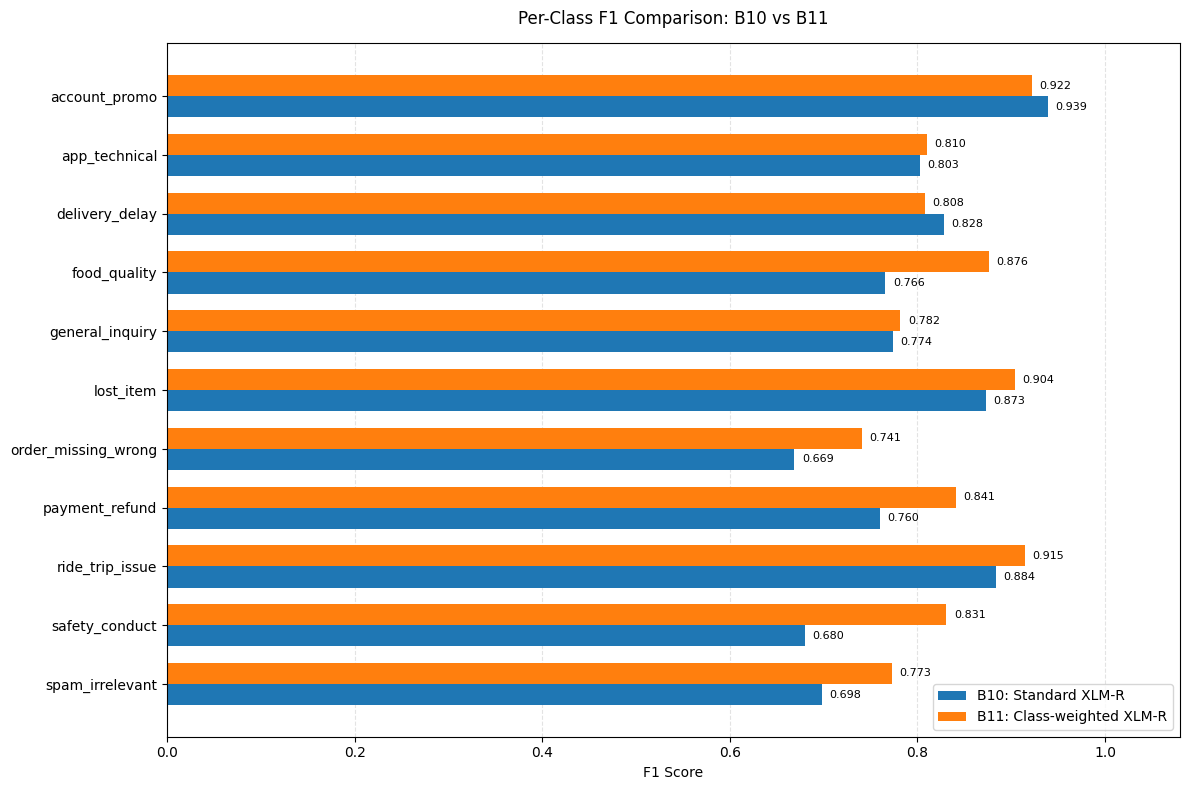

In [22]:
# Store the per-class F1 scores from B10 and B11
comparison_df = pd.DataFrame({
    "Category": [
        "account_promo",
        "app_technical",
        "delivery_delay",
        "food_quality",
        "general_inquiry",
        "lost_item",
        "order_missing_wrong",
        "payment_refund",
        "ride_trip_issue",
        "safety_conduct",
        "spam_irrelevant"
    ],
    "B10": [0.939, 0.803, 0.828, 0.766, 0.774, 0.873, 0.669, 0.760, 0.884, 0.680, 0.698],
    "B11": [0.922, 0.810, 0.808, 0.876, 0.782, 0.904, 0.741, 0.841, 0.915, 0.831, 0.773]
})

# Calculate the change in F1 score between the two models
comparison_df["Change"] = comparison_df["B11"] - comparison_df["B10"]

# Reverse the order so the first category appears at the top
comparison_df = comparison_df.iloc[::-1].reset_index(drop=True)

# Set the positions and bar height for each model
y = np.arange(len(comparison_df))
bar_height = 0.36

# Create the grouped horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    y - bar_height / 2,
    comparison_df["B10"],
    bar_height,
    label="B10: Standard XLM-R"
)
ax.barh(
    y + bar_height / 2,
    comparison_df["B11"],
    bar_height,
    label="B11: Class-weighted XLM-R"
)

# Label the categories and format the axis
ax.set_yticks(y)
ax.set_yticklabels(comparison_df["Category"])
ax.set_xlim(0, 1.08)
ax.set_xlabel("F1 Score")
ax.set_title("Per-Class F1 Comparison: B10 vs B11", pad=14)
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Add the F1 score beside each bar
for i, row in comparison_df.iterrows():
    ax.text(row["B10"] + 0.008, i - bar_height / 2,
            f'{row["B10"]:.3f}', va="center", fontsize=8)
    ax.text(row["B11"] + 0.008, i + bar_height / 2,
            f'{row["B11"]:.3f}', va="center", fontsize=8)

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

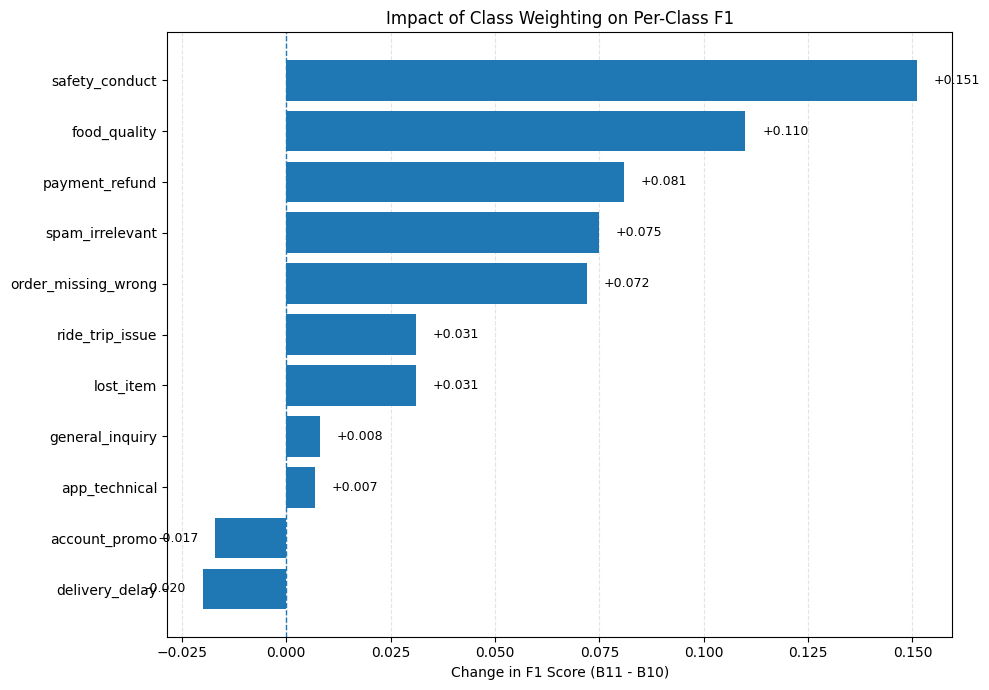

In [23]:
# Sort categories by improvement, from largest regression to largest gain
change_df = comparison_df.sort_values("Change")

# Create a horizontal chart of F1-score changes
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(change_df["Category"], change_df["Change"])

# Add a zero reference line to separate gains from regressions
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Change in F1 Score (B11 - B10)")
ax.set_title("Impact of Class Weighting on Per-Class F1")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Annotate each bar with its signed change
for bar, value in zip(bars, change_df["Change"]):
    offset = 0.004 if value >= 0 else -0.004
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [24]:
# Build a validation DataFrame with actual and predicted categories
b11_language_results = validation_df[["language", "category"]].copy()

# Add the model's predicted category labels
b11_language_results["predicted_category"] = [
    id2label[int(prediction)]
    for prediction in b11_predictions
]

# Mark whether each prediction is correct
b11_language_results["correct"] = (
    b11_language_results["category"]
    == b11_language_results["predicted_category"]
)

# Calculate accuracy and Macro-F1 separately for each language
for language, group in b11_language_results.groupby("language"):
    language_macro_f1 = f1_score(
        group["category"],
        group["predicted_category"],
        labels=labels,
        average="macro",
        zero_division=0
    )

    print(
        f"{language:10s} | "
        f"Samples: {len(group):3d} | "
        f"Accuracy: {group['correct'].mean():.4f} | "
        f"Macro-F1: {language_macro_f1:.4f}"
    )

en         | Samples: 280 | Accuracy: 0.8429 | Macro-F1: 0.8441
mixed      | Samples:  20 | Accuracy: 0.8500 | Macro-F1: 0.7900
si         | Samples: 160 | Accuracy: 0.8313 | Macro-F1: 0.7396
singlish   | Samples: 200 | Accuracy: 0.8000 | Macro-F1: 0.8319
ta         | Samples: 120 | Accuracy: 0.8917 | Macro-F1: 0.8496
tanglish   | Samples:  20 | Accuracy: 0.8000 | Macro-F1: 0.8268


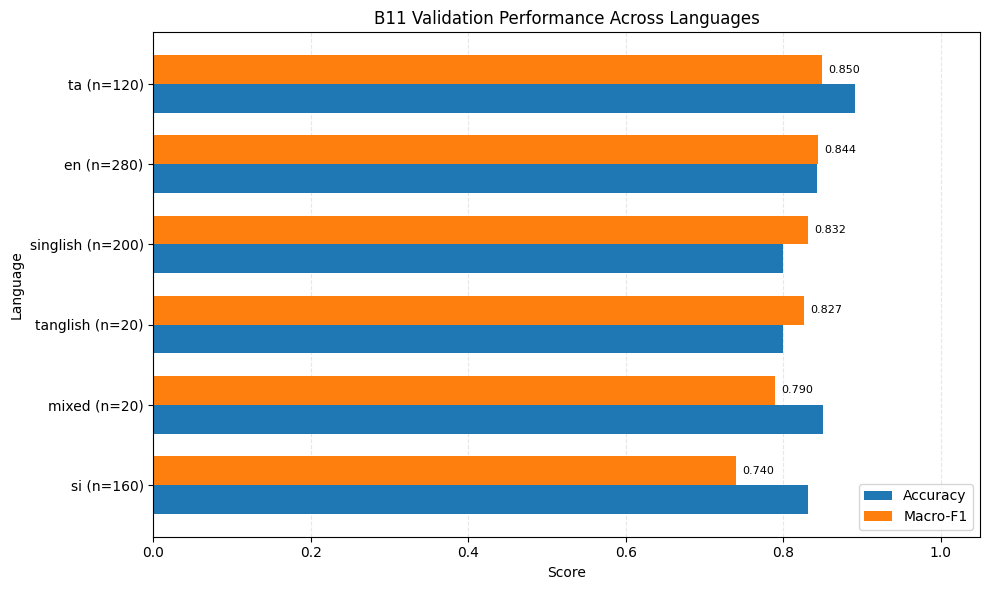

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Store the language-level results
language_plot_df = pd.DataFrame({
    "Language": ["en", "mixed", "si", "singlish", "ta", "tanglish"],
    "Samples": [280, 20, 160, 200, 120, 20],
    "Accuracy": [0.8429, 0.8500, 0.8313, 0.8000, 0.8917, 0.8000],
    "Macro-F1": [0.8441, 0.7900, 0.7396, 0.8319, 0.8496, 0.8268]
})

# Sort languages by Macro-F1 for easier comparison
language_plot_df = language_plot_df.sort_values("Macro-F1")

# Create positions for the grouped bars
y = np.arange(len(language_plot_df))
bar_height = 0.36

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Accuracy and Macro-F1
ax.barh(
    y - bar_height / 2,
    language_plot_df["Accuracy"],
    bar_height,
    label="Accuracy"
)
ax.barh(
    y + bar_height / 2,
    language_plot_df["Macro-F1"],
    bar_height,
    label="Macro-F1"
)

# Format the axes and title
ax.set_yticks(y)
ax.set_yticklabels(language_plot_df["Language"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Score")
ax.set_ylabel("Language")
ax.set_title("B11 Validation Performance Across Languages")
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Annotate the Macro-F1 bars using explicit column indexing
for i in range(len(language_plot_df)):
    score = language_plot_df["Macro-F1"].iloc[i]
    ax.text(score + 0.008, i + bar_height / 2,
            f"{score:.3f}", va="center", fontsize=8)

# Add sample counts to the category labels
ax.set_yticklabels([
    f"{row.Language} (n={row.Samples})"
    for row in language_plot_df.itertuples()
])

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

In [27]:
# Define a dedicated directory for the final B11 artifacts
B11_MODEL_DIR = PROJECT_ROOT / "models" / "xlmr_primary_weighted" / "final"
B11_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the best model selected by validation Macro-F1
weighted_trainer.save_model(str(B11_MODEL_DIR))

# Save the matching tokenizer for future inference
tokenizer.save_pretrained(str(B11_MODEL_DIR))

# Confirm where the artifacts were saved
print("B11 model and tokenizer saved to:")
print(B11_MODEL_DIR.resolve())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

B11 model and tokenizer saved to:
D:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\models\xlmr_primary_weighted\final


In [28]:
# List the saved model and tokenizer files
saved_files = sorted(
    path.name for path in B11_MODEL_DIR.iterdir() if path.is_file()
)

for filename in saved_files:
    print(filename)

# Check that the essential files exist
required_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "sentencepiece.bpe.model"
]

missing_files = [
    filename for filename in required_files
    if not (B11_MODEL_DIR / filename).exists()
]

# Report whether the essential files were found
if not missing_files:
    print("\nEssential model and tokenizer files verified.")
else:
    print("\nFiles requiring investigation:", missing_files)

config.json
model.safetensors
tokenizer.json
tokenizer_config.json
training_args.bin

Files requiring investigation: ['sentencepiece.bpe.model']


In [29]:
# Reload the tokenizer from the saved directory
test_tokenizer = AutoTokenizer.from_pretrained(
    str(B11_MODEL_DIR),
    local_files_only=True
)

# Reload the trained model from the saved directory
test_model = AutoModelForSequenceClassification.from_pretrained(
    str(B11_MODEL_DIR),
    local_files_only=True
)

# Verify the model and tokenizer
print("Tokenizer loaded:", type(test_tokenizer).__name__)
print("Model loaded:", type(test_model).__name__)
print("Number of categories:", test_model.config.num_labels)
print("Tokenizer vocabulary size:", test_tokenizer.vocab_size)
print("Model directory:", B11_MODEL_DIR.resolve())

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tokenizer loaded: XLMRobertaTokenizer
Model loaded: XLMRobertaForSequenceClassification
Number of categories: 11
Tokenizer vocabulary size: 250002
Model directory: D:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\models\xlmr_primary_weighted\final


In [30]:
# Select GPU when available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move the saved model to the selected device and enable inference mode
test_model = test_model.to(device)
test_model.eval()

# Define a reusable prediction function for a single ticket
def predict_primary_category(text):
    # Tokenize the ticket using the saved tokenizer
    inputs = test_tokenizer(
        text,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    # Move tokenized inputs to the same device as the model
    inputs = {key: value.to(device) for key, value in inputs.items()}

    # Predict without calculating gradients
    with torch.inference_mode():
        outputs = test_model(**inputs)

    # Convert logits into probabilities and select the highest
    probabilities = torch.softmax(outputs.logits, dim=-1)[0]
    predicted_id = int(torch.argmax(probabilities).item())

    # Return the predicted category and its model confidence
    return {
        "category": id2label[predicted_id],
        "confidence": float(probabilities[predicted_id].item())
    }

# Test with an illustrative customer ticket
sample_ticket = (
    "I was charged twice for the same ride. "
    "Please refund the duplicate payment."
)

# Run the prediction and display the result
prediction = predict_primary_category(sample_ticket)
print("Ticket:", sample_ticket)
print("Predicted category:", prediction["category"])
print("Model confidence:", round(prediction["confidence"], 4))

Ticket: I was charged twice for the same ride. Please refund the duplicate payment.
Predicted category: payment_refund
Model confidence: 0.9588


In [31]:
# Prepare representative tickets covering different primary categories
test_tickets = [
    {
        "text": "My food delivery has not arrived, and it is 45 minutes late.",
        "expected": "delivery_delay"
    },
    {
        "text": "I left my phone in the driver's car after the ride.",
        "expected": "lost_item"
    },
    {
        "text": "The app crashes every time I try to open my order history.",
        "expected": "app_technical"
    },
    {
        "text": "The driver threatened me during the trip and I feel unsafe.",
        "expected": "safety_conduct"
    },
    {
        "text": "I received the wrong meal instead of the one I ordered.",
        "expected": "order_missing_wrong"
    },
    {
        "text": "How can I register my restaurant as a delivery partner?",
        "expected": "general_inquiry"
    }
]

# Predict each ticket and compare with its expected category
test_results = []

for ticket in test_tickets:
    # Run the saved model on the ticket text
    result = predict_primary_category(ticket["text"])

    # Record the prediction and whether it matches the expected label
    test_results.append({
        "Expected": ticket["expected"],
        "Predicted": result["category"],
        "Confidence": round(result["confidence"], 4),
        "Correct": result["category"] == ticket["expected"]
    })

# Display the results as a table
test_results_df = pd.DataFrame(test_results)
print(test_results_df.to_string(index=False))

# Summarize the number of correct predictions
print(
    f"\nCorrect: {test_results_df['Correct'].sum()}"
    f"/{len(test_results_df)}"
)

           Expected           Predicted  Confidence  Correct
     delivery_delay      delivery_delay      0.9861     True
          lost_item           lost_item      0.8663     True
      app_technical       app_technical      0.9822     True
     safety_conduct      safety_conduct      0.8257     True
order_missing_wrong order_missing_wrong      0.9888     True
    general_inquiry     general_inquiry      0.9392     True

Correct: 6/6


In [32]:
# Inspect the availability of secondary labels in the training data
secondary_counts = train_df["secondary_category"].value_counts(dropna=False)

print("Training secondary-category distribution:")
print(secondary_counts.to_string())

print("\nTraining secondary-label coverage:")
print(f"Total tickets: {len(train_df)}")
print(
    "Tickets with secondary labels:",
    int(train_df["secondary_category"].notna().sum())
)
print(
    "Tickets without secondary labels:",
    int(train_df["secondary_category"].isna().sum())
)

# Check the corresponding distribution in validation data
print("\nValidation secondary-label distribution:")
print(validation_df["secondary_category"].value_counts(dropna=False).to_string())

Training secondary-category distribution:
secondary_category
NaN                    3600
ride_trip_issue         135
payment_refund          130
app_technical            45
delivery_delay           45
order_missing_wrong      45

Training secondary-label coverage:
Total tickets: 4000
Tickets with secondary labels: 400
Tickets without secondary labels: 3600

Validation secondary-label distribution:
secondary_category
NaN                    720
ride_trip_issue         27
payment_refund          26
app_technical            9
order_missing_wrong      9
delivery_delay           9


In [33]:
# Keep only tickets that have a secondary-category label
secondary_labeled_df = train_df[
    train_df["secondary_category"].notna()
].copy()

# Compare primary and secondary categories
primary_secondary_table = pd.crosstab(
    secondary_labeled_df["category"],
    secondary_labeled_df["secondary_category"]
)

# Display the relationship between the two labels
print("Primary vs Secondary Category Counts:")
print(primary_secondary_table)

# Calculate the proportion of each primary category assigned to each secondary category
print("\nRow-normalized proportions:")
print(
    pd.crosstab(
        secondary_labeled_df["category"],
        secondary_labeled_df["secondary_category"],
        normalize="index"
    ).round(3)
)

# Inspect a few labeled examples to understand their meaning
print("\nSample tickets with secondary labels:")
for _, row in secondary_labeled_df[
    ["text", "category", "secondary_category"]
].head(12).iterrows():
    print(f"\nText: {row['text']}")
    print(f"Primary: {row['category']}")
    print(f"Secondary: {row['secondary_category']}")

Primary vs Secondary Category Counts:
secondary_category   app_technical  delivery_delay  order_missing_wrong  \
category                                                                  
account_promo                   45               0                    0   
delivery_delay                   0               0                    0   
food_quality                     0               0                    0   
lost_item                        0               0                    0   
order_missing_wrong              0               0                    0   
payment_refund                   0              45                   45   
safety_conduct                   0               0                    0   

secondary_category   payment_refund  ride_trip_issue  
category                                              
account_promo                     0                0  
delivery_delay                   45                0  
food_quality                     45                0  
lost_item  

In [34]:
# Locate the dataset documentation
notes_path = RAW_DATA_DIR / "DATA_NOTES.md"

# Read the documentation without losing Unicode text
if notes_path.exists():
    notes_text = notes_path.read_text(encoding="utf-8")
    print(notes_text)
else:
    print("DATA_NOTES.md was not found at:", notes_path)

# RideEat multilingual workshop dataset — revision 2

This edition supersedes the earlier English-only release. All tickets are synthetic and describe the fictional RideEat platform. No real customer records were used.

Train contains 4,000 tickets and validation contains 800. Both are available as UTF-8 CSV and JSONL. Public columns, in order: ticket_id, channel, subject, text, language, category, secondary_category, is_urgent.

language is an input feature available alongside the ticket. It is not a prediction target. Values: en (English), si (predominantly Sinhala Unicode), ta (predominantly Tamil Unicode), singlish (Sinhala in Latin script with English), tanglish (Tamil in Latin script with English), mixed (native-script Sinhala or Tamil mixed with substantial English). Loanwords and brief English instructions can occur in otherwise Sinhala/Tamil tickets.

Train and validation language shares: English 35%, Singlish 25%, Sinhala 20%, Tamil 15%, Tanglish 2.5%, mixed 2.5%. All categor

In [35]:
# Check whether any secondary label matches its primary category
labeled_train = train_df[
    train_df["secondary_category"].notna()
].copy()

same_label = (
    labeled_train["category"]
    == labeled_train["secondary_category"]
)

print("Secondary labels matching primary:", int(same_label.sum()))

# Check whether any spam tickets have a secondary label
spam_with_secondary = labeled_train[
    labeled_train["category"] == "spam_irrelevant"
]

print("Spam tickets with secondary labels:", len(spam_with_secondary))

# Summarize secondary-label availability by primary category
secondary_presence = (
    train_df.assign(
        has_secondary=train_df["secondary_category"].notna()
    )
    .groupby("category")["has_secondary"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
)

print("\nSecondary-label availability by primary category:")
print(secondary_presence.to_string())

Secondary labels matching primary: 0
Spam tickets with secondary labels: 0

Secondary-label availability by primary category:
                     count  sum      mean
category                                 
payment_refund         720  135  0.187500
delivery_delay         600   45  0.075000
account_promo          360   45  0.125000
safety_conduct         160   45  0.281250
food_quality           280   45  0.160714
lost_item              200   45  0.225000
order_missing_wrong    480   40  0.083333
app_technical          320    0  0.000000
general_inquiry        200    0  0.000000
ride_trip_issue        560    0  0.000000
spam_irrelevant        120    0  0.000000


In [37]:
# Combine the available text fields and metadata into one input
def build_ticket_text(df):
    return (
        "subject " + df["subject"].fillna("").astype(str)
        + " channel " + df["channel"].fillna("").astype(str)
        + " language " + df["language"].fillna("").astype(str)
        + " text " + df["text"].fillna("").astype(str)
    )

# Create model inputs and binary targets
X_train_presence = build_ticket_text(train_df)
X_val_presence = build_ticket_text(validation_df)

y_train_presence = train_df["secondary_category"].notna().astype(int)
y_val_presence = validation_df["secondary_category"].notna().astype(int)

# Build a character n-gram model with balanced class weights
secondary_presence_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=3,
        max_features=150000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using all training tickets
secondary_presence_model.fit(
    X_train_presence,
    y_train_presence
)

# Evaluate whether the model identifies tickets with secondary labels
presence_predictions = secondary_presence_model.predict(X_val_presence)

print("Secondary-label presence classification report:")
print(classification_report(
    y_val_presence,
    presence_predictions,
    labels=[0, 1],
    target_names=["No secondary label", "Has secondary label"],
    digits=4,
    zero_division=0
))

# Display errors and correct predictions in a confusion matrix
print("Confusion matrix:")
print(confusion_matrix(
    y_val_presence,
    presence_predictions,
    labels=[0, 1]
))

Secondary-label presence classification report:
                     precision    recall  f1-score   support

 No secondary label     0.9587    1.0000    0.9789       720
Has secondary label     1.0000    0.6125    0.7597        80

           accuracy                         0.9613       800
          macro avg     0.9794    0.8063    0.8693       800
       weighted avg     0.9628    0.9613    0.9570       800

Confusion matrix:
[[720   0]
 [ 31  49]]


In [38]:
# Keep only tickets with known secondary categories
secondary_train_df = train_df[
    train_df["secondary_category"].notna()
].copy()

secondary_val_df = validation_df[
    validation_df["secondary_category"].notna()
].copy()

# Build text inputs using the same fields as the presence model
X_train_secondary = build_ticket_text(secondary_train_df)
X_val_secondary = build_ticket_text(secondary_val_df)

# Use the actual secondary-category labels as targets
y_train_secondary = secondary_train_df["secondary_category"]
y_val_secondary = secondary_val_df["secondary_category"]

# Build a character n-gram classifier with balanced class weights
secondary_category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=100000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train only on examples with known secondary labels
secondary_category_model.fit(
    X_train_secondary,
    y_train_secondary
)

# Evaluate the category classifier on labeled validation examples
secondary_predictions = secondary_category_model.predict(
    X_val_secondary
)

print("Secondary-category classification report:")
print(classification_report(
    y_val_secondary,
    secondary_predictions,
    labels=sorted(y_train_secondary.unique()),
    digits=4,
    zero_division=0
))

# Show which secondary categories are confused with one another
print("Confusion matrix:")
print(confusion_matrix(
    y_val_secondary,
    secondary_predictions,
    labels=sorted(y_train_secondary.unique())
))

# Display the label order used by the confusion matrix
print("\nLabel order:")
print(sorted(y_train_secondary.unique()))

Secondary-category classification report:
                     precision    recall  f1-score   support

      app_technical     1.0000    0.4444    0.6154         9
     delivery_delay     1.0000    0.4444    0.6154         9
order_missing_wrong     1.0000    0.4444    0.6154         9
     payment_refund     0.6047    1.0000    0.7536        26
    ride_trip_issue     0.9600    0.8889    0.9231        27

           accuracy                         0.7750        80
          macro avg     0.9129    0.6444    0.7046        80
       weighted avg     0.8580    0.7750    0.7642        80

Confusion matrix:
[[ 4  0  0  4  1]
 [ 0  4  0  5  0]
 [ 0  0  4  5  0]
 [ 0  0  0 26  0]
 [ 0  0  0  3 24]]

Label order:
['app_technical', 'delivery_delay', 'order_missing_wrong', 'payment_refund', 'ride_trip_issue']


In [39]:
# Display the primary-to-secondary label combinations in training data
print("Training primary/secondary combinations:")
print(pd.crosstab(
    secondary_train_df["category"],
    secondary_train_df["secondary_category"]
).to_string())

# Compare primary-category combinations in validation data
print("\nValidation primary/secondary combinations:")
print(pd.crosstab(
    secondary_val_df["category"],
    secondary_val_df["secondary_category"]
).to_string())

# Inspect a few misclassified validation examples
secondary_errors = secondary_val_df.copy()

# Add true and predicted secondary labels for error analysis
secondary_errors["predicted_secondary"] = secondary_predictions

# Keep only incorrect predictions
secondary_errors = secondary_errors[
    secondary_errors["secondary_category"]
    != secondary_errors["predicted_secondary"]
]

# Print representative errors with enough context to understand the issue
for _, row in secondary_errors.head(10).iterrows():
    print("\n" + "=" * 70)
    print("Primary category:", row["category"])
    print("True secondary:", row["secondary_category"])
    print("Predicted secondary:", row["predicted_secondary"])
    print("Language:", row["language"])
    print("Subject:", row["subject"])
    print("Text:", row["text"][:500])

Training primary/secondary combinations:
secondary_category   app_technical  delivery_delay  order_missing_wrong  payment_refund  ride_trip_issue
category                                                                                                
account_promo                   45               0                    0               0                0
delivery_delay                   0               0                    0              45                0
food_quality                     0               0                    0              45                0
lost_item                        0               0                    0               0               45
order_missing_wrong              0               0                    0              40                0
payment_refund                   0              45                   45               0               45
safety_conduct                   0               0                    0               0               45

Validation pr

In [40]:
# Select payment_refund tickets with known secondary labels
payment_refund_train = train_df[
    (train_df["category"] == "payment_refund")
    & train_df["secondary_category"].notna()
].copy()

payment_refund_val = validation_df[
    (validation_df["category"] == "payment_refund")
    & validation_df["secondary_category"].notna()
].copy()

# Prepare ticket text and secondary-label targets
X_pr_train = build_ticket_text(payment_refund_train)
X_pr_val = build_ticket_text(payment_refund_val)

y_pr_train = payment_refund_train["secondary_category"]
y_pr_val = payment_refund_val["secondary_category"]

# Train a character n-gram model on this narrower classification task
payment_refund_secondary_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=100000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Fit using training data only
payment_refund_secondary_model.fit(X_pr_train, y_pr_train)

# Evaluate on labeled payment_refund validation tickets
pr_predictions = payment_refund_secondary_model.predict(X_pr_val)

print("Specialized secondary-category report:")
print(classification_report(
    y_pr_val,
    pr_predictions,
    digits=4,
    zero_division=0
))

# Show the confusion matrix and its label order
pr_labels = sorted(y_pr_train.unique())

print("Label order:", pr_labels)
print(confusion_matrix(
    y_pr_val,
    pr_predictions,
    labels=pr_labels
))

Specialized secondary-category report:
                     precision    recall  f1-score   support

     delivery_delay     0.6250    0.5556    0.5882         9
order_missing_wrong     0.6250    0.5556    0.5882         9
    ride_trip_issue     0.7273    0.8889    0.8000         9

           accuracy                         0.6667        27
          macro avg     0.6591    0.6667    0.6588        27
       weighted avg     0.6591    0.6667    0.6588        27

Label order: ['delivery_delay', 'order_missing_wrong', 'ride_trip_issue']
[[5 3 1]
 [2 5 2]
 [1 0 8]]


In [41]:
# Get the true primary labels for validation tickets with secondary labels
secondary_val_primary = secondary_val_df.copy()

# Prepare the same text representation used by the saved B11 model
primary_inputs = (
    secondary_val_primary["subject"].fillna("").astype(str)
    + " "
    + secondary_val_primary["text"].fillna("").astype(str)
).tolist()

# Predict primary categories with the saved XLM-R model
primary_predictions = []

test_model.eval()

# Process tickets individually to keep GPU memory usage low
for ticket_text in primary_inputs:
    # Tokenize each ticket and limit the sequence length
    inputs = test_tokenizer(
        ticket_text,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    # Move inputs to the same device as the saved model
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # Predict without calculating gradients
    with torch.inference_mode():
        outputs = test_model(**inputs)

    # Convert the predicted class ID to its category name
    predicted_id = int(outputs.logits.argmax(dim=-1).item())
    primary_predictions.append(id2label[predicted_id])

# Compare predicted primary categories against their true labels
true_primary = secondary_val_primary["category"].tolist()

print(
    "Primary accuracy on secondary-labeled validation tickets:",
    round(accuracy_score(true_primary, primary_predictions), 4)
)

print("\nPrimary-category classification report:")
print(classification_report(
    true_primary,
    primary_predictions,
    digits=4,
    zero_division=0
))

Primary accuracy on secondary-labeled validation tickets: 0.7875

Primary-category classification report:
                     precision    recall  f1-score   support

      account_promo     1.0000    0.7778    0.8750         9
      app_technical     0.0000    0.0000    0.0000         0
     delivery_delay     0.6154    0.8889    0.7273         9
       food_quality     0.8182    1.0000    0.9000         9
          lost_item     1.0000    0.8889    0.9412         9
order_missing_wrong     0.5455    0.7500    0.6316         8
     payment_refund     0.9474    0.6667    0.7826        27
    ride_trip_issue     0.0000    0.0000    0.0000         0
     safety_conduct     1.0000    0.7778    0.8750         9

           accuracy                         0.7875        80
          macro avg     0.6585    0.6389    0.6370        80
       weighted avg     0.8731    0.7875    0.8131        80



In [43]:
# Display the text-construction function used by the secondary models
print(inspect.getsource(build_ticket_text))

# Inspect a few original training examples and their available input fields
print(
    train_df[
        ["channel", "subject", "text", "language"]
    ].head(3).to_string(index=False)
)

def build_ticket_text(df):
    return (
        "subject " + df["subject"].fillna("").astype(str)
        + " channel " + df["channel"].fillna("").astype(str)
        + " language " + df["language"].fillna("").astype(str)
        + " text " + df["text"].fillna("").astype(str)
    )

        channel subject                                                                                                                                                                                                                                                                                                                                                                                                                                                          text language
           chat     NaN                                                                                                                                                                                                                      

In [44]:
# Select validation tickets that have known secondary labels
secondary_val_primary = secondary_val_df.copy()

# Use only the text field, matching B11's training input
primary_inputs = (
    secondary_val_primary["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

# Store the corrected primary-category predictions
primary_predictions = []

# Set the saved model to evaluation mode
test_model.eval()

# Predict tickets individually to limit GPU memory usage
for ticket_text in primary_inputs:
    # Tokenize the ticket body using the training configuration
    inputs = test_tokenizer(
        ticket_text,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    # Move tokenized inputs to the model's device
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # Run inference without calculating gradients
    with torch.inference_mode():
        outputs = test_model(**inputs)

    # Convert the predicted class ID to its category name
    predicted_id = int(outputs.logits.argmax(dim=-1).item())
    primary_predictions.append(id2label[predicted_id])

# Compare predictions with the true primary categories
true_primary = secondary_val_primary["category"].tolist()

print(
    "Primary accuracy on secondary-labeled validation tickets:",
    round(accuracy_score(true_primary, primary_predictions), 4)
)

# Display per-category performance for this validation subset
print(classification_report(
    true_primary,
    primary_predictions,
    digits=4,
    zero_division=0
))

Primary accuracy on secondary-labeled validation tickets: 0.8
                     precision    recall  f1-score   support

      account_promo     1.0000    0.7778    0.8750         9
      app_technical     0.0000    0.0000    0.0000         0
     delivery_delay     0.6154    0.8889    0.7273         9
       food_quality     0.9000    1.0000    0.9474         9
          lost_item     1.0000    0.8889    0.9412         9
order_missing_wrong     0.5833    0.8750    0.7000         8
     payment_refund     0.9474    0.6667    0.7826        27
    ride_trip_issue     0.0000    0.0000    0.0000         0
     safety_conduct     1.0000    0.7778    0.8750         9

           accuracy                         0.8000        80
          macro avg     0.6718    0.6528    0.6498        80
       weighted avg     0.8861    0.8000    0.8253        80



In [46]:
# Define primary categories with one observed secondary category in training
unique_secondary_by_primary = {
    "account_promo": "app_technical",
    "delivery_delay": "payment_refund",
    "food_quality": "payment_refund",
    "lost_item": "ride_trip_issue",
    "order_missing_wrong": "payment_refund",
    "safety_conduct": "ride_trip_issue",
}

# Predict secondary-label presence for all validation tickets
presence_predictions = secondary_presence_model.predict(X_val_presence)

# Predict secondary categories for the 80 tickets with known secondary labels
category_predictions = secondary_category_model.predict(X_val_secondary)

# Store predictions for validation tickets with known secondary labels
end_to_end_predictions = []

for idx, row in secondary_val_df.iterrows():
    # Find this ticket's position in the full validation dataframe
    full_position = validation_df.index.get_loc(idx)

    # Return no secondary label if the presence detector predicts none
    if presence_predictions[full_position] == 0:
        end_to_end_predictions.append(None)
        continue

    # Retrieve the primary category predicted by B11 for this ticket
    predicted_primary = primary_by_id[row["ticket_id"]]

    # Use a constrained prediction when training data shows one observed option
    if predicted_primary in unique_secondary_by_primary:
        predicted_secondary = unique_secondary_by_primary[predicted_primary]
    else:
        # Construct exactly one text string for the secondary classifier
        ticket_text = build_ticket_text(
            secondary_val_primary.loc[[idx]]
        ).iloc[0]

        # Predict the secondary category from the ticket text
        predicted_secondary = secondary_category_model.predict(
            [ticket_text]
        )[0]

    # Save the final secondary-category prediction
    end_to_end_predictions.append(predicted_secondary)

# Represent missing predictions explicitly for evaluation
true_secondary = secondary_val_df["secondary_category"].tolist()
predicted_secondary_eval = [
    pred if pred is not None else "__no_secondary__"
    for pred in end_to_end_predictions
]

# Evaluate all secondary-category outcomes in this labeled subset
evaluation_labels = sorted(
    train_df["secondary_category"].dropna().unique().tolist()
) + ["__no_secondary__"]

print("End-to-end secondary-category report:")
print(classification_report(
    true_secondary,
    predicted_secondary_eval,
    labels=evaluation_labels,
    digits=4,
    zero_division=0
))

# Display the confusion matrix with the same label order
print("Confusion matrix:")
print(confusion_matrix(
    true_secondary,
    predicted_secondary_eval,
    labels=evaluation_labels
))

print("\nLabel order:")
print(evaluation_labels)

End-to-end secondary-category report:
                     precision    recall  f1-score   support

      app_technical     1.0000    0.4444    0.6154         9
     delivery_delay     1.0000    0.1111    0.2000         9
order_missing_wrong     1.0000    0.1111    0.2000         9
     payment_refund     0.7407    0.7692    0.7547        26
    ride_trip_issue     1.0000    0.5926    0.7442        27
   __no_secondary__     0.0000    0.0000    0.0000         0

           accuracy                         0.5250        80
          macro avg     0.7901    0.3381    0.4190        80
       weighted avg     0.9157    0.5250    0.6107        80

Confusion matrix:
[[ 4  0  0  0  0  5]
 [ 0  1  0  4  0  4]
 [ 0  0  1  2  0  6]
 [ 0  0  0 20  0  6]
 [ 0  0  0  1 16 10]
 [ 0  0  0  0  0  0]]

Label order:
['app_technical', 'delivery_delay', 'order_missing_wrong', 'payment_refund', 'ride_trip_issue', '__no_secondary__']


In [47]:
# Predict secondary-label presence for every validation ticket
all_presence_predictions = secondary_presence_model.predict(X_val_presence)

# Predict secondary categories for every validation ticket
all_category_predictions = secondary_category_model.predict(X_val_presence)

# Combine the presence and category predictions
all_secondary_predictions = [
    category if has_secondary == 1 else None
    for has_secondary, category in zip(
        all_presence_predictions,
        all_category_predictions
    )
]

# Convert missing predictions to an explicit label for evaluation
true_secondary_all = [
    label if pd.notna(label) else "__no_secondary__"
    for label in validation_df["secondary_category"]
]

predicted_secondary_all = [
    label if label is not None else "__no_secondary__"
    for label in all_secondary_predictions
]

# Include all five secondary categories and the no-secondary outcome
evaluation_labels = sorted(
    train_df["secondary_category"].dropna().unique().tolist()
) + ["__no_secondary__"]

# Evaluate across all 800 validation tickets
print("Full validation secondary-label report:")
print(classification_report(
    true_secondary_all,
    predicted_secondary_all,
    labels=evaluation_labels,
    digits=4,
    zero_division=0
))

# Display the confusion matrix
print("Confusion matrix:")
print(confusion_matrix(
    true_secondary_all,
    predicted_secondary_all,
    labels=evaluation_labels
))

print("\nLabel order:")
print(evaluation_labels)

Full validation secondary-label report:
                     precision    recall  f1-score   support

      app_technical     1.0000    0.4444    0.6154         9
     delivery_delay     1.0000    0.4444    0.6154         9
order_missing_wrong     1.0000    0.3333    0.5000         9
     payment_refund     0.9524    0.7692    0.8511        26
    ride_trip_issue     1.0000    0.6296    0.7727        27
   __no_secondary__     0.9587    1.0000    0.9789       720

           accuracy                         0.9600       800
          macro avg     0.9852    0.6035    0.7222       800
       weighted avg     0.9613    0.9600    0.9542       800

Confusion matrix:
[[  4   0   0   0   0   5]
 [  0   4   0   1   0   4]
 [  0   0   3   0   0   6]
 [  0   0   0  20   0   6]
 [  0   0   0   0  17  10]
 [  0   0   0   0   0 720]]

Label order:
['app_technical', 'delivery_delay', 'order_missing_wrong', 'payment_refund', 'ride_trip_issue', '__no_secondary__']


In [48]:
# Prepare ticket text using subject, channel, language, and body
X_train_urgency = build_ticket_text(train_df)
X_val_urgency = build_ticket_text(validation_df)

# Convert urgency targets to binary integers
y_train_urgency = train_df["is_urgent"].astype(int)
y_val_urgency = validation_df["is_urgent"].astype(int)

# Build a character n-gram classifier with balanced class weights
urgency_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=3,
        max_features=150000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train the urgency classifier on the training split
urgency_model.fit(X_train_urgency, y_train_urgency)

# Predict urgency for validation tickets
urgency_predictions = urgency_model.predict(X_val_urgency)

# Report performance for both urgent and non-urgent tickets
print("Urgency classification report:")
print(classification_report(
    y_val_urgency,
    urgency_predictions,
    labels=[0, 1],
    target_names=["Not urgent", "Urgent"],
    digits=4,
    zero_division=0
))

# Inspect false positives and false negatives
print("Confusion matrix:")
print(confusion_matrix(
    y_val_urgency,
    urgency_predictions,
    labels=[0, 1]
))

# Record the positive-class F1 score for experiment comparison
print(
    "Urgent-class F1:",
    round(f1_score(y_val_urgency, urgency_predictions, pos_label=1), 4)
)

Urgency classification report:
              precision    recall  f1-score   support

  Not urgent     0.9835    0.9931    0.9883       720
      Urgent     0.9315    0.8500    0.8889        80

    accuracy                         0.9788       800
   macro avg     0.9575    0.9215    0.9386       800
weighted avg     0.9783    0.9788    0.9783       800

Confusion matrix:
[[715   5]
 [ 12  68]]
Urgent-class F1: 0.8889


In [49]:

# Copy validation data for error analysis
urgency_errors = validation_df.copy()

# Add the true and predicted urgency labels
urgency_errors["true_urgent"] = y_val_urgency.to_numpy()
urgency_errors["predicted_urgent"] = urgency_predictions

# Identify false negatives and false positives
false_negatives = urgency_errors[
    (urgency_errors["true_urgent"] == 1)
    & (urgency_errors["predicted_urgent"] == 0)
]

false_positives = urgency_errors[
    (urgency_errors["true_urgent"] == 0)
    & (urgency_errors["predicted_urgent"] == 1)
]

# Display missed urgent tickets
print("FALSE NEGATIVES: urgent tickets predicted as not urgent")
for _, row in false_negatives.iterrows():
    print("\n" + "=" * 70)
    print("Language:", row["language"])
    print("Primary category:", row["category"])
    print("Subject:", row["subject"])
    print("Text:", row["text"][:700])

# Display false alarms
print("\nFALSE POSITIVES: non-urgent tickets predicted as urgent")
for _, row in false_positives.iterrows():
    print("\n" + "=" * 70)
    print("Language:", row["language"])
    print("Primary category:", row["category"])
    print("Subject:", row["subject"])
    print("Text:", row["text"][:700])

FALSE NEGATIVES: urgent tickets predicted as not urgent

Language: en
Primary category: food_quality
Subject: A matter for support
Text: Dear RideEat support,

This is the first message I have sent about this matter.
Here are the details of my request.
I have kept the confirmation rather than deleting it from the device.
I do not remember the exact minute I opened the service, but I have the reference.
My elderly parent is repeatedly vomiting after eating the food.
Can the support desk follow up?

Regards,
A customer

On an earlier date, the support desk wrote:
> The earlier unrelated case is resolved.
> The status is complete; our reception has received no delivery.
> Please describe only your new request above.

Language: en
Primary category: safety_conduct
Subject: A matter for support
Text: dear rideeat    suport
pls advise on    this situation    the drivr appears
drunk
and  is    unable to    keep  the
car in its  lane  journey    was  also    terminated b4
the  chosen destinatio

In [55]:
# Calculate decision scores from the already-trained urgency model
urgency_scores = urgency_model.decision_function(X_val_urgency)

# Test the default and several lower decision thresholds
thresholds = [0.0, -0.1, -0.2, -0.3, -0.5]

# Store results for each threshold
threshold_results = []

for threshold in thresholds:
    # Predict urgent when the decision score meets the threshold
    threshold_predictions = (urgency_scores >= threshold).astype(int)

    # Calculate urgent-class metrics and error counts
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val_urgency, threshold_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val_urgency, threshold_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val_urgency, threshold_predictions, zero_division=0
        ),
        "false_positives": int(
            ((y_val_urgency == 0) & (threshold_predictions == 1)).sum()
        ),
        "false_negatives": int(
            ((y_val_urgency == 1) & (threshold_predictions == 0)).sum()
        )
    })

# Display the comparison table
threshold_results_df = pd.DataFrame(threshold_results)
print(threshold_results_df.round(4).to_string(index=False))

 threshold  precision  recall     f1  false_positives  false_negatives
       0.0     0.9315  0.8500 0.8889                5               12
      -0.1     0.8554  0.8875 0.8712               12                9
      -0.2     0.7200  0.9000 0.8000               28                8
      -0.3     0.5448  0.9125 0.6822               61                7
      -0.5     0.3391  0.9750 0.5032              152                2


### Urgency Classification Threshold Experiment

The character TF-IDF and Linear SVM urgency classifier was evaluated at five decision thresholds. The default threshold of 0.0 achieved an urgent-class precision of 93.15%, recall of 85.00%, and F1-score of 0.8889, with 5 false positives and 12 false negatives.

Lowering the threshold to -0.1 increased recall to 88.75%, reducing false negatives to 9, but increased false positives to 12 and reduced F1-score to 0.8712.

**Decision:** Retain the default threshold of 0.0 as the current operating point because it provides the strongest F1-score and substantially fewer false alarms. Consider -0.1 if higher urgent-ticket recall is prioritized. These results are from the validation set; final performance must be measured on the held-out test set.


In [56]:
# Display fitted model variables relevant to inference
for name, value in sorted(globals().items()):
    if any(term in name.lower() for term in [
        "secondary", "presence", "urgent", "urgency"
    ]):
        # Print the variable name and its type
        print(f"{name}: {type(value).__name__}")

X_train_presence: Series
X_train_secondary: Series
X_train_urgency: Series
X_val_presence: Series
X_val_secondary: Series
X_val_urgency: Series
all_presence_predictions: ndarray
all_secondary_predictions: list
payment_refund_secondary_model: Pipeline
predicted_secondary: str
predicted_secondary_all: list
predicted_secondary_eval: list
presence_predictions: ndarray
primary_secondary_table: DataFrame
secondary_category_model: Pipeline
secondary_counts: Series
secondary_errors: DataFrame
secondary_labeled_df: DataFrame
secondary_predictions: ndarray
secondary_presence: DataFrame
secondary_presence_model: Pipeline
secondary_train_df: DataFrame
secondary_val_df: DataFrame
secondary_val_primary: DataFrame
spam_with_secondary: DataFrame
true_secondary: list
true_secondary_all: list
unique_secondary_by_primary: dict
urgency_errors: DataFrame
urgency_model: Pipeline
urgency_predictions: ndarray
urgency_scores: ndarray
y_train_presence: Series
y_train_secondary: Series
y_train_urgency: Series
y_

In [57]:
# Find all fitted scikit-learn pipelines in the notebook
from sklearn.pipeline import Pipeline

for name, value in sorted(globals().items()):
    # List pipeline variables without printing training data
    if isinstance(value, Pipeline):
        print(f"{name}: Pipeline")
        print(f"  Steps: {list(value.named_steps.keys())}")

payment_refund_secondary_model: Pipeline
  Steps: ['tfidf', 'classifier']
secondary_category_model: Pipeline
  Steps: ['tfidf', 'classifier']
secondary_presence_model: Pipeline
  Steps: ['tfidf', 'classifier']
urgency_model: Pipeline
  Steps: ['tfidf', 'classifier']


In [59]:
# Define the model output directory relative to the project root
model_dir = Path.cwd() / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save each fitted secondary-label pipeline
models_to_save = {
    "secondary_presence_classifier.joblib": secondary_presence_model,
    "secondary_category_classifier.joblib": secondary_category_model,
}

for filename, model in models_to_save.items():
    # Save the complete pipeline, including its vectorizer
    output_path = model_dir / filename
    joblib.dump(model, output_path)

    # Confirm the artifact was written successfully
    assert output_path.is_file(), f"Failed to save {filename}"
    print(f"Saved: {output_path.resolve()}")

Saved: D:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\notebooks\models\secondary_presence_classifier.joblib
Saved: D:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\notebooks\models\secondary_category_classifier.joblib


In [62]:
# Define the notebook and project model directories
notebook_model_dir = Path.cwd() / "models"
project_model_dir = Path.cwd().parent / "models"

# Create the project-level model directory if needed
project_model_dir.mkdir(parents=True, exist_ok=True)

# Move both secondary-label model files
for filename in [
    "secondary_presence_classifier.joblib",
    "secondary_category_classifier.joblib",
]:
    # Identify the source and destination paths
    source = notebook_model_dir / filename
    destination = project_model_dir / filename

    # Move the file and verify the destination
    if source.is_file():
        shutil.move(str(source), str(destination))
        print(f"Moved: {destination}")
    elif destination.is_file():
        print(f"Already exists: {destination}")
    else:
        raise FileNotFoundError(f"Could not find {filename}")

# Display the final project model directory
print("\nProject model directory:", project_model_dir.resolve())

Moved: d:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\models\secondary_presence_classifier.joblib
Moved: d:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\models\secondary_category_classifier.joblib

Project model directory: D:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\models


In [63]:
# List the saved secondary-label model artifacts
for path in sorted(project_model_dir.glob("*.joblib")):
    print(f"{path.name}: {path.stat().st_size / (1024 ** 2):.2f} MB")

secondary_category_classifier.joblib: 1.84 MB
secondary_presence_classifier.joblib: 1.97 MB


In [64]:
# Inspect fitted pipelines to identify the urgency classifier
from sklearn.pipeline import Pipeline

for name, value in sorted(globals().items()):
    # Only inspect scikit-learn pipelines
    if isinstance(value, Pipeline):
        # Display the pipeline name and its component steps
        print(f"{name}: {list(value.named_steps.keys())}")

model: ['tfidf', 'classifier']
payment_refund_secondary_model: ['tfidf', 'classifier']
secondary_category_model: ['tfidf', 'classifier']
secondary_presence_model: ['tfidf', 'classifier']
urgency_model: ['tfidf', 'classifier']


In [65]:
# Set the project-level models directory
model_dir = Path.cwd().parent / "models"

# Define the output path for the urgency model
urgency_model_path = model_dir / "urgency_classifier.joblib"

# Save the fitted urgency pipeline, including TF-IDF and Linear SVM
joblib.dump(urgency_model, urgency_model_path)

# Verify that the model file was saved
assert urgency_model_path.is_file(), "Urgency model was not saved."

# Display the saved file location and size
print(f"Saved: {urgency_model_path.resolve()}")
print(f"Size: {urgency_model_path.stat().st_size / (1024 ** 2):.2f} MB")

Saved: D:\TensorForge_Competition\Customer-Support-Ticket-Classification-and-Routing-System-\models\urgency_classifier.joblib
Size: 1.97 MB


In [66]:
# Locate the project-level model directory
model_dir = Path.cwd().parent / "models"

# List all three saved scikit-learn models
model_files = [
    "secondary_presence_classifier.joblib",
    "secondary_category_classifier.joblib",
    "urgency_classifier.joblib",
]

for filename in model_files:
    # Load the saved pipeline to verify it can be restored
    model_path = model_dir / filename
    loaded_model = joblib.load(model_path)

    # Confirm the loaded model has the expected pipeline structure
    print(f"{filename}: loaded successfully")
    print(f"  Pipeline steps: {list(loaded_model.named_steps.keys())}")

secondary_presence_classifier.joblib: loaded successfully
  Pipeline steps: ['tfidf', 'classifier']
secondary_category_classifier.joblib: loaded successfully
  Pipeline steps: ['tfidf', 'classifier']
urgency_classifier.joblib: loaded successfully
  Pipeline steps: ['tfidf', 'classifier']


In [67]:
# Locate the saved models
model_dir = Path.cwd().parent / "models"

# Load the secondary-label and urgency pipelines
presence_model = joblib.load(
    model_dir / "secondary_presence_classifier.joblib"
)
secondary_model = joblib.load(
    model_dir / "secondary_category_classifier.joblib"
)
urgency_pipeline = joblib.load(
    model_dir / "urgency_classifier.joblib"
)

# Create example ticket inputs using the same format as training
sample_tickets = [
    "subject  channel chat language en text I was charged twice for the same ride. Please refund the duplicate payment.",
    "subject  channel chat language en text My food delivery has not arrived and it is already very late.",
    "subject  channel chat language en text My elderly parent is repeatedly vomiting after eating the food. Please help immediately."
]

# Predict whether each ticket has a secondary category
presence_predictions = presence_model.predict(sample_tickets)

# Predict secondary categories for the sample tickets
secondary_predictions = secondary_model.predict(sample_tickets)

# Predict urgency using the saved model's decision scores
urgency_scores = urgency_pipeline.decision_function(sample_tickets)

# Apply the selected urgency threshold
urgency_predictions = urgency_scores >= 0.0

# Display predictions for each sample
for i, ticket in enumerate(sample_tickets):
    print(f"\nTicket {i + 1}: {ticket}")
    print(f"Secondary label present: {bool(presence_predictions[i])}")
    print(f"Predicted secondary category: {secondary_predictions[i]}")
    print(f"Urgency score: {urgency_scores[i]:.4f}")
    print(f"Predicted urgent: {bool(urgency_predictions[i])}")


Ticket 1: subject  channel chat language en text I was charged twice for the same ride. Please refund the duplicate payment.
Secondary label present: False
Predicted secondary category: payment_refund
Urgency score: -1.2796
Predicted urgent: False

Ticket 2: subject  channel chat language en text My food delivery has not arrived and it is already very late.
Secondary label present: False
Predicted secondary category: delivery_delay
Urgency score: -0.2631
Predicted urgent: False

Ticket 3: subject  channel chat language en text My elderly parent is repeatedly vomiting after eating the food. Please help immediately.
Secondary label present: False
Predicted secondary category: ride_trip_issue
Urgency score: 1.1386
Predicted urgent: True


In [70]:
# Locate the saved primary model directory
model_dir = Path.cwd().parent / "models" / "xlmr_primary_weighted" / "final"

# List the files required to load the primary model
print("Primary model files:")
for path in sorted(model_dir.iterdir()):
    if path.is_file():
        print(f"  {path.name}: {path.stat().st_size / (1024 ** 2):.2f} MB")

# Inspect the saved category mapping
config_path = model_dir / "config.json"

with config_path.open("r", encoding="utf-8") as file:
    config = json.load(file)

# Display the mappings stored in the model configuration
print("\nSaved label mapping:")
print(json.dumps(config.get("id2label", {}), indent=2))

Primary model files:
  config.json: 0.00 MB
  model.safetensors: 1060.71 MB
  tokenizer.json: 16.31 MB
  tokenizer_config.json: 0.00 MB
  training_args.bin: 0.00 MB

Saved label mapping:
{
  "0": "account_promo",
  "1": "app_technical",
  "2": "delivery_delay",
  "3": "food_quality",
  "4": "general_inquiry",
  "5": "lost_item",
  "6": "order_missing_wrong",
  "7": "payment_refund",
  "8": "ride_trip_issue",
  "9": "safety_conduct",
  "10": "spam_irrelevant"
}


In [72]:
# Add the project root to Python's import path.
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Load the saved models.
from src.inference.predictor import TicketPredictor

predictor = TicketPredictor()

# Test three different ticket types.
sample_tickets = [
    {
        "ticket_id": "TEST-001",
        "channel": "chat",
        "language": "en",
        "subject": "",
        "text": "I was charged twice for the same ride. Please refund the duplicate payment.",
    },
    {
        "ticket_id": "TEST-002",
        "channel": "chat",
        "language": "en",
        "subject": "",
        "text": "My food delivery has not arrived and it is already very late.",
    },
    {
        "ticket_id": "TEST-003",
        "channel": "chat",
        "language": "en",
        "subject": "",
        "text": "My elderly parent is repeatedly vomiting after eating the food. Please help immediately.",
    },
]

# Generate predictions without retraining any model.
predictions = predictor.predict_batch(sample_tickets)

# Display the outputs for inspection.
for prediction in predictions:
    print(prediction)

Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

{'ticket_id': 'TEST-001', 'category': 'payment_refund', 'category_confidence': 0.9588, 'secondary_category': None, 'is_urgent': False, 'urgency_score': -1.2796}
{'ticket_id': 'TEST-002', 'category': 'delivery_delay', 'category_confidence': 0.9854, 'secondary_category': None, 'is_urgent': False, 'urgency_score': -0.2631}
{'ticket_id': 'TEST-003', 'category': 'food_quality', 'category_confidence': 0.9725, 'secondary_category': None, 'is_urgent': True, 'urgency_score': 1.1386}
